# Tugas Praktikum Reinforcement Learning: Agent Bermain Blackjack

| Nama | NRP |
|------|-----|
| Benedictus Ryu Gunawan | 5054251001 |

## Deskripsi Project

Agent belajar bermain **Blackjack** melawan dealer. Tujuannya mendapat total kartu sedekat mungkin ke 21 tanpa lewat (*bust*), dan lebih tinggi dari dealer.
Agent tidak diberi tahu strategi yang benar. Agent hanya bermain ribuan kali, menerima hasil menang/kalah, lalu memperbaiki strateginya.

Aturan yang dipakai (mengikuti Sutton & Barto, Example 5.1):

- Dek tak terbatas (kartu diambil dengan pengembalian). Kartu 2–10 bernilai sesuai angka, J/Q/K bernilai 10, As bernilai 1 atau 11.
- Pemain dan dealer masing-masing dapat 2 kartu. Satu kartu dealer terlihat.
- Pemain memilih **hit** (ambil kartu) atau **stick** (berhenti). Lewat 21 berarti langsung kalah.
- Setelah pemain stick, dealer mengambil kartu sampai totalnya minimal 17, lalu total dibandingkan.
- Tidak ada double down, split, atau taruhan. Blackjack natural dibayar sama dengan menang biasa.

Dua algoritma dibandingkan: **Monte Carlo Control** dan **Q-Learning**. Pembandingnya ada tiga: policy **random**, strategi **"ikut dealer"** (hit sampai 17), dan **policy optimal** dari buku Sutton & Barto (Figure 5.2).

| Konsep RL | Di project ini |
|---|---|
| Agent | Pemain (`MonteCarloAgent` / `QLearningAgent`) |
| Environment | Meja Blackjack beserta dealer (`BlackjackEnv`) |
| State | `(total kartu pemain, kartu dealer yang terlihat, punya As yang bisa dihitung 11?)` |
| Action | `0 = stick`, `1 = hit` |
| Reward | +1 menang, 0 seri, -1 kalah (diberikan di akhir game, langkah lain 0) |
| Policy | epsilon-greedy saat training, greedy (`argmax Q`) saat evaluasi |
| Value | Tabel Q(s, a) dan V(s) = max_a Q(s, a), yaitu perkiraan rata-rata hasil dari suatu state |
| Pembelajaran | MC: update dari hasil akhir satu game penuh. Q-Learning: update temporal-difference tiap langkah |
| Evaluasi | Rata-rata reward, persentase menang/seri/kalah pada 100.000 game, dan perbandingan dengan policy optimal |

# 1. Import Library

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

SEED = 42
np.set_printoptions(precision=3, suppress=True)
STICK, HIT = 0, 1

# 2. Environment: `BlackjackEnv`

Interface dibuat mirip Gymnasium: `reset()` membagikan kartu dan mengembalikan state awal, `step(action)` mengembalikan `(next_state, reward, done)`.
State `(player_sum, dealer_card, usable_ace)`:

- `player_sum`: total kartu pemain (4–21). As dihitung 11 bila tidak membuat bust.
- `dealer_card`: kartu dealer yang terlihat (1 = As, 2–10).
- `usable_ace`: 1 bila pemain punya As yang sedang dihitung 11, 0 bila tidak.

In [2]:
class BlackjackEnv:
    def __init__(self, seed=None):
        self.rng = random.Random(seed)

    def draw(self):
        return min(self.rng.randint(1, 13), 10)  # J, Q, K bernilai 10

    @staticmethod
    def hand_value(cards):
        total = sum(cards)
        usable = 1 in cards and total + 10 <= 21
        return (total + 10 if usable else total), int(usable)

    def state(self):
        total, usable = self.hand_value(self.player)
        return (total, self.dealer[0], usable)

    def reset(self):
        self.player = [self.draw(), self.draw()]
        self.dealer = [self.draw(), self.draw()]
        return self.state()

    def step(self, action):
        if action == HIT:
            self.player.append(self.draw())
            if self.hand_value(self.player)[0] > 21:
                return self.state(), -1, True   # bust
            return self.state(), 0, False

        # STICK: dealer bermain sampai total >= 17
        while self.hand_value(self.dealer)[0] < 17:
            self.dealer.append(self.draw())
        p, d = self.hand_value(self.player)[0], self.hand_value(self.dealer)[0]
        reward = 1 if d > 21 or p > d else (0 if p == d else -1)
        return self.state(), reward, True


env = BlackjackEnv(seed=SEED)
for i in range(3):
    s, done = env.reset(), False
    print(f'Game {i + 1}: kartu pemain {env.player}, kartu dealer terlihat {env.dealer[0]}, state awal {s}')
    while not done:
        a = HIT if s[0] < 17 else STICK
        s, r, done = env.step(a)
        print(f'   action={"hit" if a else "stick"} -> state {s}, reward {r}')
    print(f'   kartu akhir pemain {env.player}, kartu dealer {env.dealer}')

Game 1: kartu pemain [10, 2], kartu dealer terlihat 1, state awal (12, 1, 0)
   action=hit -> state (17, 1, 0), reward 0
   action=stick -> state (17, 1, 0), reward -1
   kartu akhir pemain [10, 2, 5], kartu dealer [1, 10]
Game 2: kartu pemain [4, 4], kartu dealer terlihat 3, state awal (8, 3, 0)
   action=hit -> state (10, 3, 0), reward 0
   action=hit -> state (20, 3, 0), reward 0
   action=stick -> state (20, 3, 0), reward 1
   kartu akhir pemain [4, 4, 2, 10], kartu dealer [3, 10, 10]
Game 3: kartu pemain [9, 2], kartu dealer terlihat 10, state awal (11, 10, 0)
   action=hit -> state (12, 10, 0), reward 0
   action=hit -> state (13, 10, 0), reward 0
   action=hit -> state (15, 10, 0), reward 0
   action=hit -> state (19, 10, 0), reward 0
   action=stick -> state (19, 10, 0), reward 1
   kartu akhir pemain [9, 2, 1, 1, 2, 4], kartu dealer [10, 7]


# 3. Agent

Q-table berbentuk array `Q[player_sum, dealer_card, usable_ace, action]` berukuran `22 x 11 x 2 x 2`.
Kedua agent memakai policy **epsilon-greedy** dengan epsilon tetap 0.1 saat training.

- **Monte Carlo Control (every-visit, on-policy):** tunggu sampai game selesai, lalu setiap pasangan (s, a) yang dilalui di-update ke rata-rata hasil akhirnya:
  `Q(s,a) ← Q(s,a) + (1/N(s,a)) [ G − Q(s,a) ]`.
- **Q-Learning (off-policy, TD):** update setiap langkah memakai estimasi state berikutnya:
  `Q(s,a) ← Q(s,a) + α [ r + γ · max_a' Q(s',a') − Q(s,a) ]`, dengan γ = 1 (game pendek, tidak perlu diskon).

Sumber rumus: Sutton & Barto, *Reinforcement Learning: An Introduction* (2nd ed.), Bab 5.3–5.4 (Monte Carlo Control) dan Bab 6.5 (Q-Learning).

In [3]:
class BaseAgent:
    def __init__(self, epsilon=0.1, seed=None):
        self.Q = np.zeros((22, 11, 2, 2))
        self.epsilon = epsilon
        self.rng = random.Random(seed)

    def act(self, s, greedy=False):
        if not greedy and self.rng.random() < self.epsilon:
            return self.rng.randint(0, 1)
        q = self.Q[s]
        if q[0] == q[1]:
            return self.rng.randint(0, 1)  # tie-break acak
        return int(q[1] > q[0])


class MonteCarloAgent(BaseAgent):
    def __init__(self, **kw):
        super().__init__(**kw)
        self.N = np.zeros_like(self.Q)

    def play_and_learn(self, env):
        s, done, trajectory = env.reset(), False, []
        while not done:
            a = self.act(s)
            s2, r, done = env.step(a)
            trajectory.append((s, a))
            s = s2
        G = r  # reward hanya di akhir dan gamma = 1, jadi return semua langkah = reward akhir
        for s, a in trajectory:
            self.N[s + (a,)] += 1
            self.Q[s + (a,)] += (G - self.Q[s + (a,)]) / self.N[s + (a,)]
        return G


class QLearningAgent(BaseAgent):
    def __init__(self, alpha=0.01, gamma=1.0, **kw):
        super().__init__(**kw)
        self.alpha, self.gamma = alpha, gamma

    def play_and_learn(self, env):
        s, done = env.reset(), False
        while not done:
            a = self.act(s)
            s2, r, done = env.step(a)
            target = r + (0 if done else self.gamma * self.Q[s2].max())
            self.Q[s + (a,)] += self.alpha * (target - self.Q[s + (a,)])
            s = s2
        return r

# 4. Policy Pembanding

- **Random:** hit atau stick dengan peluang 50:50.
- **Ikut dealer:** hit sampai total minimal 17, sama seperti aturan dealer.
- **Optimal (Sutton & Barto, Figure 5.2):** policy optimal untuk aturan yang sama persis, disalin dari buku sebagai acuan.

In [4]:
def random_policy(s, rng=random.Random(SEED)):
    return rng.randint(0, 1)


def dealer_policy(s):
    return HIT if s[0] < 17 else STICK


def optimal_policy(s):
    total, dealer, usable = s
    if usable:
        if total >= 19: return STICK
        if total == 18: return STICK if 2 <= dealer <= 8 else HIT
        return HIT
    if total >= 17: return STICK
    if total >= 13: return STICK if 2 <= dealer <= 6 else HIT
    if total == 12: return STICK if 4 <= dealer <= 6 else HIT
    return HIT


def evaluate(policy, n_games=100_000, seed=0):
    env = BlackjackEnv(seed=seed)
    rewards = np.empty(n_games)
    for i in range(n_games):
        s, done = env.reset(), False
        while not done:
            s, r, done = env.step(policy(s))
        rewards[i] = r
    return {'mean_reward': rewards.mean(), 'win': (rewards == 1).mean(),
            'draw': (rewards == 0).mean(), 'lose': (rewards == -1).mean()}

# 5. Training (Interaksi Agent–Environment)

Setiap agent bermain **500.000 game**, diulang dengan **3 seed** agar hasil tidak kebetulan.
Setiap 25.000 game, policy greedy saat itu dievaluasi pada 20.000 game baru untuk melihat perkembangan strateginya.

In [5]:
N_EPISODES = 500_000
CHECKPOINT = 25_000
N_RUNS = 3

results = {}
for name, cls in [('Monte Carlo', MonteCarloAgent), ('Q-Learning', QLearningAgent)]:
    runs = []
    for run in range(N_RUNS):
        env = BlackjackEnv(seed=SEED + run)
        agent = cls(seed=SEED + run)
        train_rewards, curve = np.empty(N_EPISODES), []
        for ep in range(N_EPISODES):
            train_rewards[ep] = agent.play_and_learn(env)
            if (ep + 1) % CHECKPOINT == 0:
                greedy = lambda s, a=agent: a.act(s, greedy=True)
                curve.append(evaluate(greedy, 20_000, seed=999)['mean_reward'])
        runs.append({'agent': agent, 'train_rewards': train_rewards, 'curve': np.array(curve)})
    results[name] = runs
    print(f'{name:12s} selesai')

Monte Carlo  selesai


Q-Learning   selesai


# 6. Evaluasi

## 6.1 Hasil Akhir pada 100.000 Game

In [6]:
baselines = {'Random': random_policy, 'Ikut dealer': dealer_policy, 'Optimal (S&B)': optimal_policy}
final = {name: evaluate(p) for name, p in baselines.items()}
for name, runs in results.items():
    evs = [evaluate(lambda s, a=r['agent']: a.act(s, greedy=True)) for r in runs]
    final[name] = {k: np.mean([e[k] for e in evs]) for k in evs[0]}
    final[name]['std'] = np.std([e['mean_reward'] for e in evs])

print(f"{'Policy':14s} | {'rata2 reward':>12s} | {'menang':>7s} | {'seri':>6s} | {'kalah':>6s}")
print('-' * 58)
for name, e in final.items():
    extra = f"  (std antar seed {e['std']:.4f})" if 'std' in e else ''
    print(f"{name:14s} | {e['mean_reward']:12.4f} | {e['win']:6.1%} | {e['draw']:5.1%} | {e['lose']:5.1%}{extra}")

Policy         | rata2 reward |  menang |   seri |  kalah
----------------------------------------------------------
Random         |      -0.3988 |  27.9% |  4.3% | 67.8%
Ikut dealer    |      -0.0798 |  40.7% | 10.7% | 48.6%
Optimal (S&B)  |      -0.0442 |  43.1% |  9.4% | 47.5%
Monte Carlo    |      -0.0500 |  42.9% |  9.1% | 47.9%  (std antar seed 0.0012)
Q-Learning     |      -0.0490 |  42.9% |  9.3% | 47.8%  (std antar seed 0.0014)


## 6.2 Kurva Pembelajaran

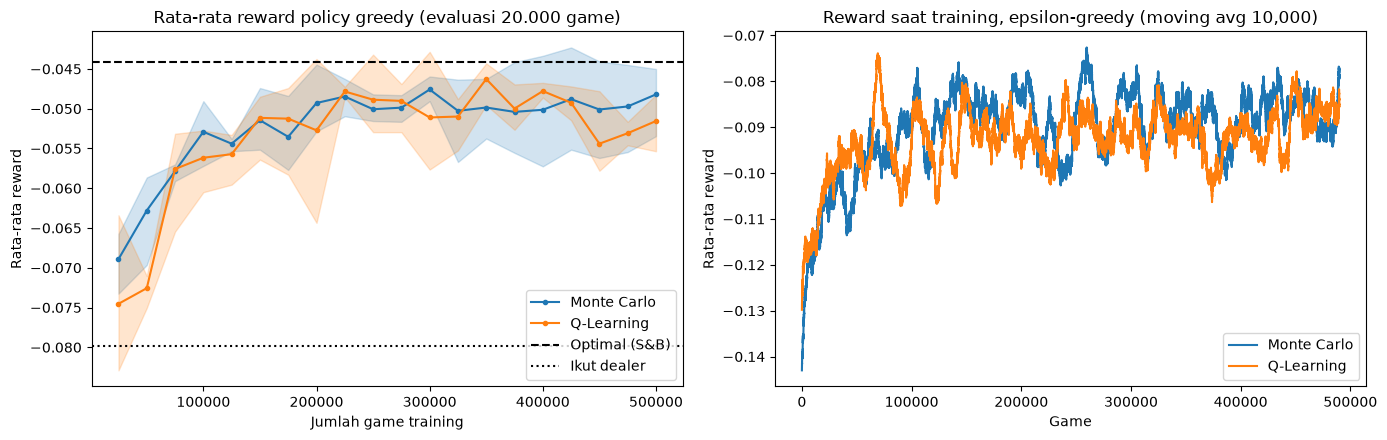

In [7]:
colors = {'Monte Carlo': 'tab:blue', 'Q-Learning': 'tab:orange'}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

x = np.arange(1, N_EPISODES // CHECKPOINT + 1) * CHECKPOINT
for name, runs in results.items():
    C = np.array([r['curve'] for r in runs])
    axes[0].plot(x, C.mean(0), marker='o', ms=3, label=name, color=colors[name])
    axes[0].fill_between(x, C.min(0), C.max(0), alpha=0.2, color=colors[name])
for name, ls in [('Optimal (S&B)', '--'), ('Ikut dealer', ':')]:
    axes[0].axhline(final[name]['mean_reward'], color='k', ls=ls, label=name)
axes[0].set_title('Rata-rata reward policy greedy (evaluasi 20.000 game)')
axes[0].set_xlabel('Jumlah game training'); axes[0].set_ylabel('Rata-rata reward'); axes[0].legend()

w = 10_000
for name, runs in results.items():
    R = np.mean([np.convolve(r['train_rewards'], np.ones(w) / w, mode='valid') for r in runs], axis=0)
    axes[1].plot(R, label=name, color=colors[name])
axes[1].set_title(f'Reward saat training, epsilon-greedy (moving avg {w:,})')
axes[1].set_xlabel('Game'); axes[1].set_ylabel('Rata-rata reward'); axes[1].legend()
plt.tight_layout(); plt.show()

## 6.3 Policy yang Dipelajari vs Policy Optimal

Setiap kotak adalah satu state (total kartu pemain 12–21 vs kartu dealer). Hijau = **stick**, merah = **hit**.
State dengan total di bawah 12 tidak digambar karena hit selalu aman di sana (tidak mungkin bust).

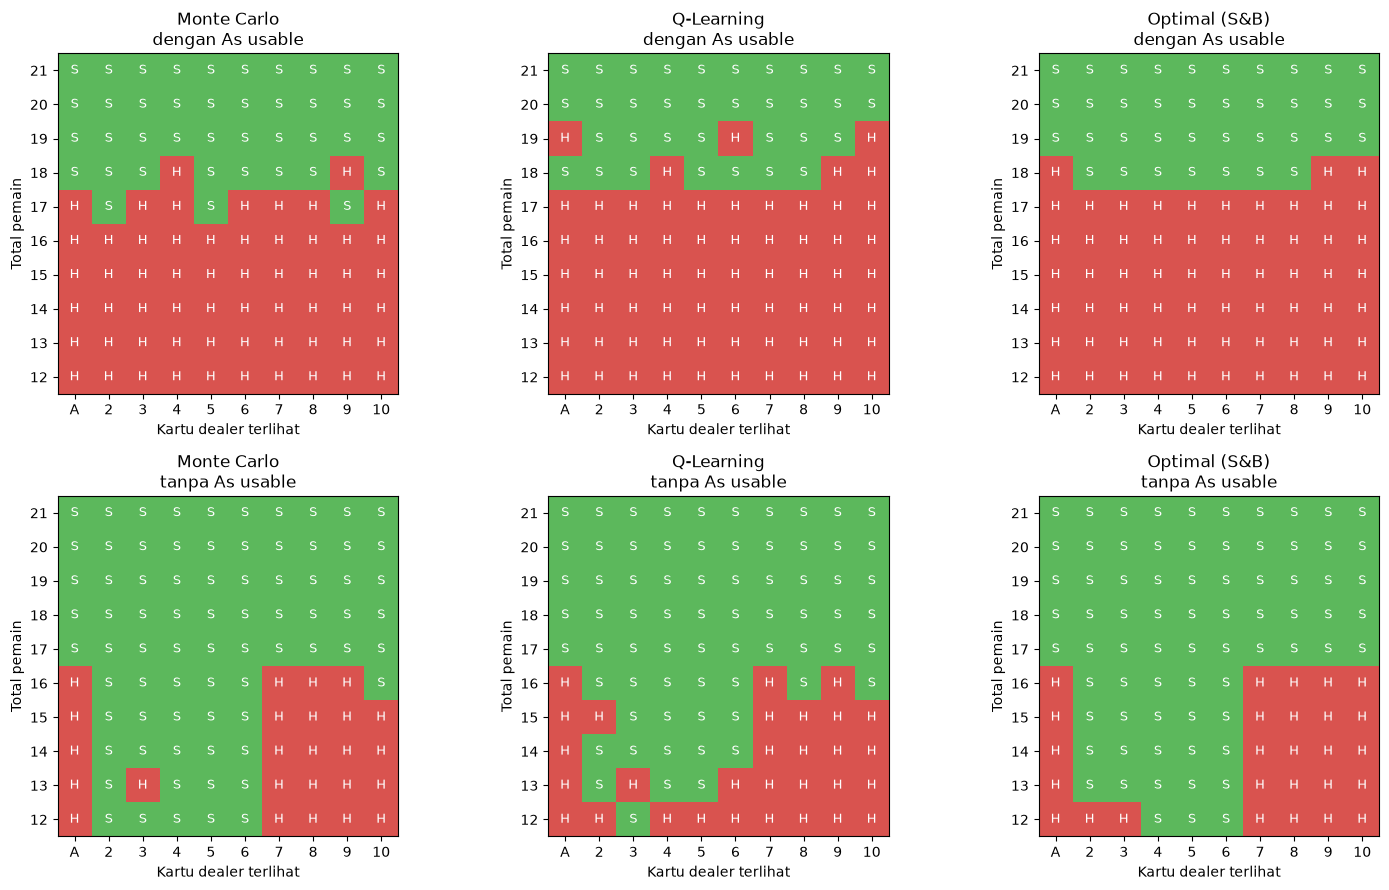

In [8]:
SUMS, DEALERS = range(12, 22), range(1, 11)

def policy_grid(policy, usable):
    return np.array([[policy((t, d, usable)) for d in DEALERS] for t in SUMS])

def greedy_of(agent):
    return lambda s: int(agent.Q[s][1] > agent.Q[s][0])

policies = {'Monte Carlo': greedy_of(results['Monte Carlo'][0]['agent']),
            'Q-Learning': greedy_of(results['Q-Learning'][0]['agent']),
            'Optimal (S&B)': optimal_policy}

cmap = ListedColormap(['#5cb85c', '#d9534f'])
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for row, usable in enumerate([1, 0]):
    for col, (name, pol) in enumerate(policies.items()):
        ax = axes[row, col]
        G = policy_grid(pol, usable)
        ax.imshow(G, cmap=cmap, vmin=0, vmax=1, origin='lower')
        for i in range(G.shape[0]):
            for j in range(G.shape[1]):
                ax.text(j, i, 'H' if G[i, j] else 'S', ha='center', va='center', color='white', fontsize=9)
        ax.set_xticks(range(10)); ax.set_xticklabels(['A'] + [str(d) for d in range(2, 11)])
        ax.set_yticks(range(10)); ax.set_yticklabels(list(SUMS))
        ax.set_xlabel('Kartu dealer terlihat'); ax.set_ylabel('Total pemain')
        ax.set_title(f"{name}\n{'dengan' if usable else 'tanpa'} As usable")
plt.tight_layout(); plt.show()

Seberapa mirip policy hasil belajar dengan policy optimal (dihitung pada 200 state total 12–21):

In [9]:
for name, runs in results.items():
    agree = []
    for r in runs:
        g = greedy_of(r['agent'])
        same = [policy_grid(g, u) == policy_grid(optimal_policy, u) for u in (0, 1)]
        agree.append(np.mean(same))
    print(f'{name:12s} kesamaan dengan optimal per seed: {[f"{a:.1%}" for a in agree]}')

# state mana saja yang beda (seed 0)
for name in results:
    g = greedy_of(results[name][0]['agent'])
    diff = [(t, d, u) for u in (0, 1) for t in SUMS for d in DEALERS if g((t, d, u)) != optimal_policy((t, d, u))]
    print(f'\n{name} (seed 0) beda di {len(diff)} state:', diff)

Monte Carlo  kesamaan dengan optimal per seed: ['95.0%', '96.5%', '94.5%']
Q-Learning   kesamaan dengan optimal per seed: ['93.0%', '93.0%', '95.0%']

Monte Carlo (seed 0) beda di 10 state: [(12, 2, 0), (12, 3, 0), (13, 3, 0), (16, 10, 0), (17, 2, 1), (17, 5, 1), (17, 9, 1), (18, 1, 1), (18, 4, 1), (18, 10, 1)]

Q-Learning (seed 0) beda di 14 state: [(12, 3, 0), (12, 4, 0), (12, 5, 0), (12, 6, 0), (13, 3, 0), (13, 6, 0), (15, 2, 0), (16, 8, 0), (16, 10, 0), (18, 1, 1), (18, 4, 1), (19, 1, 1), (19, 6, 1), (19, 10, 1)]


## 6.4 Value Function V(s) = max_a Q(s, a)

V(s) adalah perkiraan rata-rata hasil akhir bila bermain dari state s dengan policy greedy (+1 = pasti menang, -1 = pasti kalah).

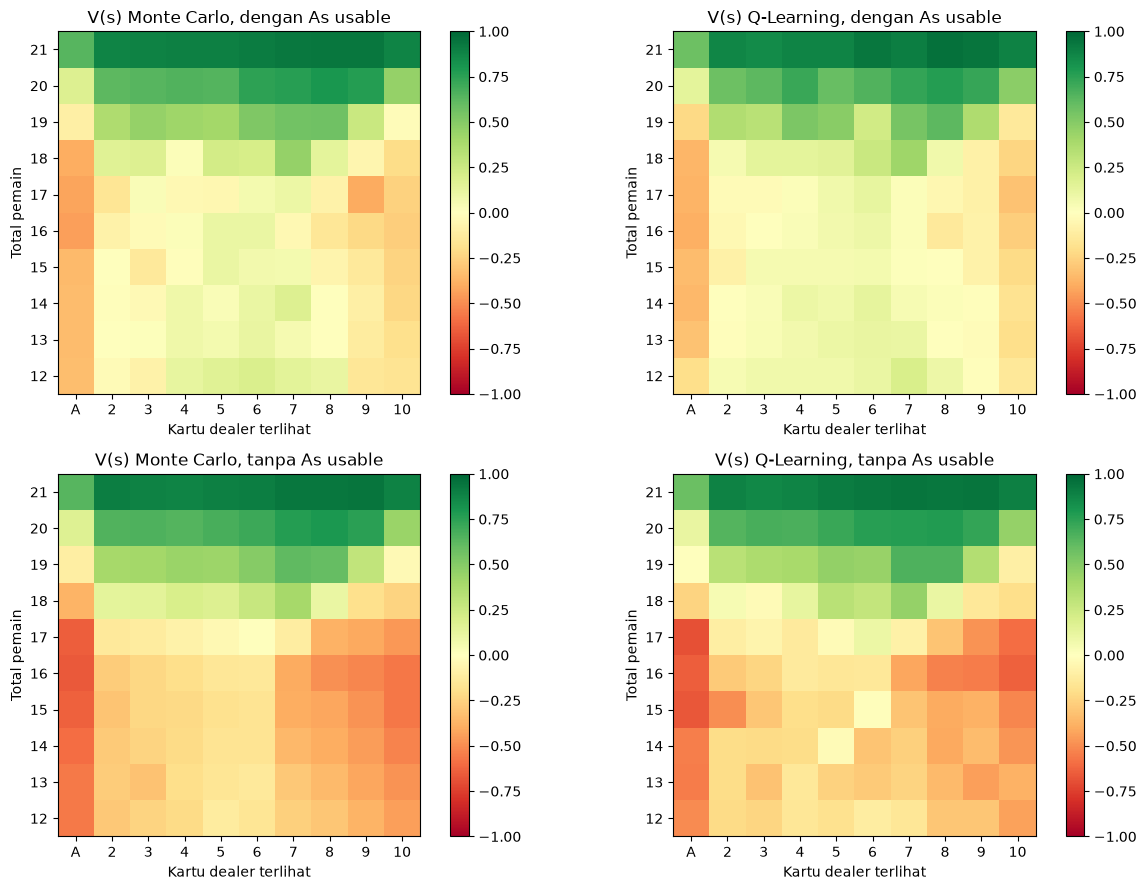

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for col, name in enumerate(['Monte Carlo', 'Q-Learning']):
    Q = results[name][0]['agent'].Q
    for row, usable in enumerate([1, 0]):
        ax = axes[row, col]
        V = Q[12:22, 1:11, usable].max(-1)
        im = ax.imshow(V, cmap='RdYlGn', vmin=-1, vmax=1, origin='lower')
        ax.set_xticks(range(10)); ax.set_xticklabels(['A'] + [str(d) for d in range(2, 11)])
        ax.set_yticks(range(10)); ax.set_yticklabels(list(SUMS))
        ax.set_xlabel('Kartu dealer terlihat'); ax.set_ylabel('Total pemain')
        ax.set_title(f"V(s) {name}, {'dengan' if usable else 'tanpa'} As usable")
        plt.colorbar(im, ax=ax, fraction=0.04)
plt.tight_layout(); plt.show()

In [11]:
Q = results['Monte Carlo'][0]['agent'].Q
for s in [(20, 10, 0), (16, 10, 0), (16, 6, 0), (12, 4, 0), (18, 9, 1)]:
    print(f'state {s}: Q(stick)={Q[s][0]:+.3f}  Q(hit)={Q[s][1]:+.3f}  -> {"hit" if Q[s][1] > Q[s][0] else "stick"}'
          f'  (optimal: {"hit" if optimal_policy(s) else "stick"})')

state (20, 10, 0): Q(stick)=+0.434  Q(hit)=-0.856  -> stick  (optimal: stick)
state (16, 10, 0): Q(stick)=-0.569  Q(hit)=-0.610  -> stick  (optimal: hit)
state (16, 6, 0): Q(stick)=-0.142  Q(hit)=-0.509  -> stick  (optimal: stick)
state (12, 4, 0): Q(stick)=-0.211  Q(hit)=-0.318  -> stick  (optimal: stick)
state (18, 9, 1): Q(stick)=-0.105  Q(hit)=-0.058  -> hit  (optimal: hit)


# 7. Analisis

Angka di bawah berasal dari run notebook ini (seed 42–44, 500.000 game training per agent). Karena seed tetap, menjalankan ulang notebook menghasilkan angka yang sama.

**1. Agent belajar dari interaksi saja.**
Policy random kalah 67.8% dengan rata-rata reward -0.399. Setelah training, Monte Carlo dan Q-Learning mencapai rata-rata reward -0.050 dan -0.049 (menang sekitar 42.9%, kalah sekitar 47.8%).
Hasil ini jauh lebih baik dari strategi "ikut dealer" (-0.080) dan sangat dekat dengan policy optimal dari buku (-0.044). Selisihnya sekitar 0.005 per game.
Rata-rata reward tetap negatif karena Blackjack memang menguntungkan bandar: pemain yang bust langsung kalah walaupun dealer nanti juga bust. Jadi tujuan agent adalah meminimalkan kekalahan, bukan menjadi untung.

**2. Proses belajar.**
Pada kurva policy greedy, kedua agent sudah lebih baik dari "ikut dealer" sejak checkpoint pertama (25.000 game, sekitar -0.07). Kurva naik cepat sampai sekitar 200.000 game, lalu mendatar di sekitar -0.048 sampai -0.050.
Kurva reward training (kanan) lebih rendah, sekitar -0.08 sampai -0.09, karena saat training agent masih memilih action acak 10% waktu (epsilon = 0.1). Ini contoh nyata biaya eksplorasi.
Kurva bergoyang naik-turun karena hasil Blackjack sangat acak. Bahkan policy yang sama memberi rata-rata reward yang berbeda sekitar ±0.005 bila dievaluasi pada 20.000 game.

**3. Policy yang dipelajari.**
Policy hasil belajar sama dengan policy optimal pada 94.5–96.5% state (Monte Carlo) dan 93–95% state (Q-Learning).
Pola utamanya berhasil ditemukan tanpa diajari:
- Tanpa As usable: stick di 17 ke atas. Untuk total 13–16, stick bila dealer menunjukkan 2–6 (dealer kemungkinan bust), dan hit bila dealer menunjukkan 7–A.
- Dengan As usable: agent berani hit sampai 17, bahkan 18 melawan dealer 9/10/A, karena As bisa berubah jadi 1 sehingga hit tidak bisa langsung bust.

State yang berbeda dari optimal hampir semuanya **state perbatasan** yang Q(stick) dan Q(hit)-nya hampir sama. Contoh: di state (16, dealer 10, tanpa As), Monte Carlo memberi Q(stick) = -0.569 dan Q(hit) = -0.610. Kedua pilihan sama-sama buruk dan selisihnya lebih kecil dari noise estimasi. Kesalahan di state seperti ini hampir tidak mengurangi reward.
State dengan As usable juga lebih jarang muncul, jadi estimasinya lebih noisy. Ini terlihat dari bagian atas grid "dengan As usable" yang punya lebih banyak perbedaan.

**4. Value function.**
V(s) tinggi (hijau) di total 20–21 dan rendah (merah) di total 12–17 ketika dealer menunjukkan 7–A. Kolom As dealer paling merah, karena dealer yang memegang As paling kuat.
Memiliki As usable menaikkan nilai state, karena pemain bisa hit dengan lebih aman.

**5. Monte Carlo vs Q-Learning.**
Hasil akhir keduanya praktis sama: -0.0500 vs -0.0490, dengan selisih lebih kecil dari variasi antar seed (std sekitar 0.001).
Monte Carlo sedikit lebih mirip optimal dan heatmap V(s)-nya lebih halus. Q-Learning memakai α = 0.01 konstan, jadi estimasinya terus bergoyang mengikuti game terbaru. Monte Carlo memakai rata-rata 1/N, jadi estimasinya makin stabil seiring bertambahnya data.
Blackjack cocok untuk Monte Carlo karena game-nya pendek (1–4 langkah) dan reward hanya ada di akhir. Keunggulan Q-Learning (bisa update sebelum episode selesai) tidak terlalu berpengaruh di sini.

# 8. Kesimpulan

- Agent berhasil belajar bermain Blackjack hanya dari hasil menang/kalah. Rata-rata reward membaik dari -0.399 (random) menjadi sekitar -0.049, lebih baik dari strategi "ikut dealer" (-0.080) dan hampir menyamai policy optimal (-0.044).
- Policy yang dipelajari 93–96.5% identik dengan policy optimal Sutton & Barto. Perbedaannya hanya di state perbatasan yang nilai kedua action-nya hampir sama.
- Value function menggambarkan permainan dengan masuk akal: total tinggi bernilai tinggi, kartu dealer kuat (7–A) menurunkan nilai, dan As usable menaikkan nilai.
- Monte Carlo dan Q-Learning sama baiknya di masalah ini. Monte Carlo sedikit lebih stabil karena game pendek dan reward hanya ada di akhir.
- Keterbatasan: aturan disederhanakan (dek tak terbatas, tanpa double/split/taruhan). Tidak ada strategi yang bisa membuat pemain untung jangka panjang dengan aturan ini, karena policy optimal pun masih rugi sekitar 4.4% per game.

# Referensi

- Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press. Example 5.1 (aturan Blackjack), Figure 5.2 (policy optimal yang dipakai sebagai pembanding), Bab 5 (Monte Carlo Control), Bab 6.5 (Q-Learning).
- Interface `reset()`/`step()` meniru gaya API Gymnasium `Blackjack-v1` (https://gymnasium.farama.org/environments/toy_text/blackjack/), tetapi environment ditulis sendiri tanpa library tersebut.